## 1. Import the libraries

In [4]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt

## 2. Load the dataset

In [5]:
df = pd.read_csv("cars_dataset.csv.zip")

## 3. Look at the data

In [6]:
df.head()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,Make
0,A1,2017,12500,Manual,15735,Petrol,150.0,55.4,1.4,audi
1,A6,2016,16500,Automatic,36203,Diesel,20.0,64.2,2.0,audi
2,A1,2016,11000,Manual,29946,Petrol,30.0,55.4,1.4,audi
3,A4,2017,16800,Automatic,25952,Diesel,145.0,67.3,2.0,audi
4,A3,2019,17300,Manual,1998,Petrol,145.0,49.6,1.0,audi


In [7]:
df.tail()

,model,year,price,transmission,mileage,fuelType,tax,mpg,engineSize,Make
72430,I30,2016,8680,Manual,25906,Diesel,0.0,78.4,1.6,Hyundai
72431,I40,2015,7830,Manual,59508,Diesel,30.0,65.7,1.7,Hyundai
72432,I10,2017,6830,Manual,13810,Petrol,20.0,60.1,1.0,Hyundai
72433,Tucson,2018,13994,Manual,23313,Petrol,145.0,44.8,1.6,Hyundai
72434,Tucson,2016,15999,Automatic,11472,Diesel,125.0,57.6,1.7,Hyundai


In [8]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 72435 entries, 0 to 72434
Data columns (total 10 columns):
 #   Column        Non-Null Count  Dtype  
---  ------        --------------  -----  
 0   model         72435 non-null  object 
 1   year          72435 non-null  int64  
 2   price         72435 non-null  int64  
 3   transmission  72435 non-null  object 
 4   mileage       72435 non-null  int64  
 5   fuelType      72435 non-null  object 
 6   tax           72435 non-null  float64
 7   mpg           72435 non-null  float64
 8   engineSize    72435 non-null  float64
 9   Make          72435 non-null  object 
dtypes: float64(3), int64(3), object(4)
memory usage: 5.5+ MB


In [9]:
df.describe()

,year,price,mileage,tax,mpg,engineSize
count,72435.000000,72435.000000,72435.000000,72435.000000,72435.000000,72435.000000
mean,2017.073666,16580.158708,23176.517057,116.953407,55.852480,1.635650
std,2.101252,9299.028754,21331.515562,64.045533,17.114391,0.561535
min,1996.000000,495.000000,1.000000,0.000000,0.300000,0.000000
25%,2016.000000,10175.000000,7202.500000,30.000000,47.900000,1.200000
50%,2017.000000,14495.000000,17531.000000,145.000000,55.400000,1.600000
75%,2019.000000,20361.000000,32449.000000,145.000000,62.800000,2.000000
max,2020.000000,145000.000000,323000.000000,580.000000,470.800000,6.600000


## 4. Check data quality
These checks show missing values and exact duplicate rows before cleaning.

In [10]:
print("Rows and columns before cleaning:", df.shape)
print("Duplicate rows:", df.duplicated().sum())
print("Missing values in each column:")
print(df.isnull().sum())

Rows and columns before cleaning: (72435, 10)
Duplicate rows: 842
Missing values in each column:
model           0
year            0
price           0
transmission    0
mileage         0
fuelType        0
tax             0
mpg             0
engineSize      0
Make            0
dtype: int64


## 5. Clean the data
There are no missing values in the supplied file, so no values need to be filled. Remove exact duplicate rows and make the brand names use consistent capitalization.

In [11]:
df = df.drop_duplicates()
df["Make"] = df["Make"].replace({"audi": "Audi", "vw": "VW", "toyota": "Toyota", "skoda": "Skoda"})
print("Rows and columns after cleaning:", df.shape)

Rows and columns after cleaning: (71593, 10)


## 6. Numerical and categorical columns

In [12]:
print("Numerical columns:")
print(df.select_dtypes(include="number").columns)
print("Categorical columns:")
print(df.select_dtypes(include="object").columns)

Numerical columns:
Index(['year', 'price', 'mileage', 'tax', 'mpg', 'engineSize'], dtype='object')
Categorical columns:
Index(['model', 'transmission', 'fuelType', 'Make'], dtype='object')


## 7. Summary statistics

In [13]:
print("Numerical summary:")
print(df.describe())
print("Categorical summary:")
print(df.describe(include="object"))

Numerical summary:
               year          price        mileage           tax           mpg  \
count  71593.000000   71593.000000   71593.000000  71593.000000  71593.000000   
mean    2017.061500   16557.395625   23270.376084    116.859819     55.891774   
std        2.102418    9295.483474   21268.084737     64.169175     17.153909   
min     1996.000000     495.000000       1.000000      0.000000      0.300000   
25%     2016.000000   10160.000000    7373.000000     30.000000     47.900000   
50%     2017.000000   14490.000000   17689.000000    145.000000     55.400000   
75%     2019.000000   20192.000000   32548.000000    145.000000     62.800000   
max     2020.000000  145000.000000  323000.000000    580.000000    470.800000   

         engineSize  
count  71593.000000  
mean       1.636571  
std        0.562012  
min        0.000000  
25%        1.200000  
50%        1.600000  
75%        2.000000  
max        6.600000  
Categorical summary:
          model transmission fue

In [14]:
print("Number of cars by fuel type:")
print(df["fuelType"].value_counts())

Number of cars by fuel type:
fuelType
Petrol      39844
Diesel      28619
Hybrid       2887
Other         238
Electric        5
Name: count, dtype: int64


In [15]:
print("Number of cars by brand:")
print(df["Make"].value_counts())

Number of cars by brand:
Make
Ford       17810
VW         14893
BMW        10664
Audi       10565
Toyota      6699
Skoda       6188
Hyundai     4774
Name: count, dtype: int64


In [16]:
print("Median price by fuel type:")
print(df.groupby("fuelType")["price"].median())

Median price by fuel type:
fuelType
Diesel      16591.0
Electric    17400.0
Hybrid      17998.0
Other       16450.0
Petrol      12490.0
Name: price, dtype: float64


## 8. Chart 1 - Number of cars by fuel type

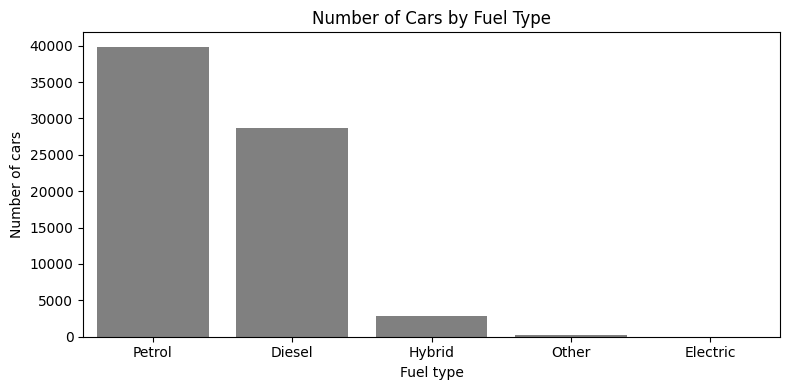

In [17]:
plt.figure(figsize=(8, 4))
sns.countplot(x="fuelType", data=df, color="gray")
plt.title("Number of Cars by Fuel Type")
plt.xlabel("Fuel type")
plt.ylabel("Number of cars")
plt.tight_layout()
plt.show()

**Observation:** Petrol and diesel make up most of the dataset. There are very few electric-car records, so their results should be treated carefully.

## 9. Chart 2 - Price distribution

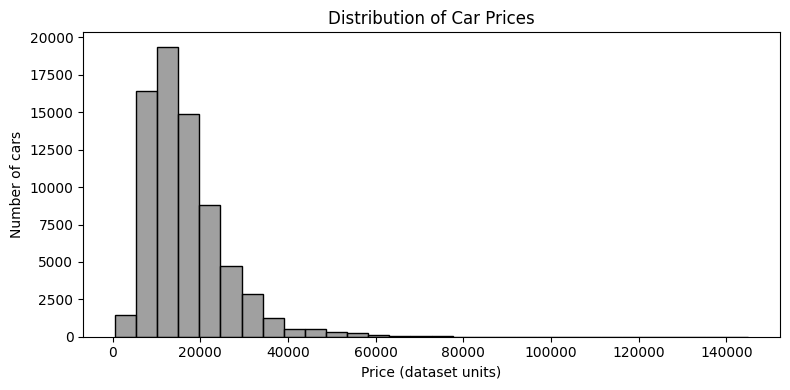

In [18]:
plt.figure(figsize=(8, 4))
sns.histplot(df["price"], bins=30, color="gray")
plt.title("Distribution of Car Prices")
plt.xlabel("Price (dataset units)")
plt.ylabel("Number of cars")
plt.tight_layout()
plt.show()

**Observation:** Most cars are in the lower-to-middle part of the price range, while a smaller number of cars have much higher prices.

## 10. Chart 3 - Check price outliers

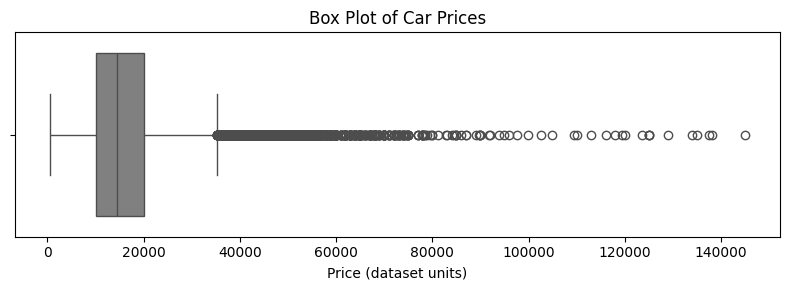

In [19]:
plt.figure(figsize=(8, 3))
sns.boxplot(x=df["price"], color="gray")
plt.title("Box Plot of Car Prices")
plt.xlabel("Price (dataset units)")
plt.tight_layout()
plt.show()

**Observation:** The box plot shows some unusually high prices. An outlier is not automatically a mistake; it should be checked before deciding what to do with it.

## 11. Chart 4 - Price by fuel type

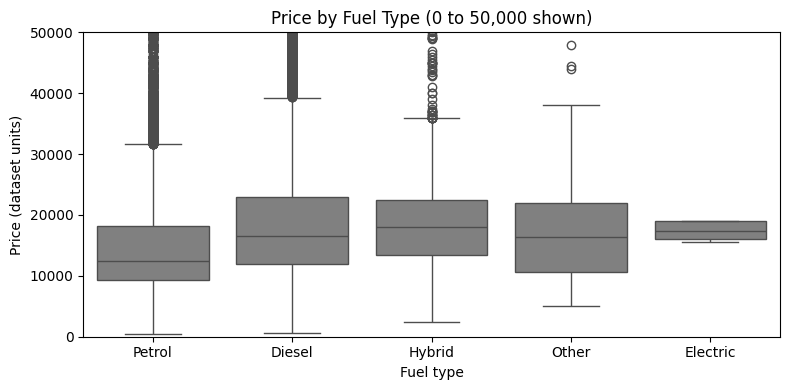

In [20]:
plt.figure(figsize=(8, 4))
sns.boxplot(x="fuelType", y="price", data=df, color="gray")
plt.ylim(0, 50000)
plt.title("Price by Fuel Type (0 to 50,000 shown)")
plt.xlabel("Fuel type")
plt.ylabel("Price (dataset units)")
plt.tight_layout()
plt.show()

**Observation:** The price distributions differ across fuel groups. This is a relationship only; it does not prove that fuel type alone causes the price difference. The display is limited to 50,000 so the middle of the groups is easier to compare.

## 12. Chart 5 - Manufacturing year and price

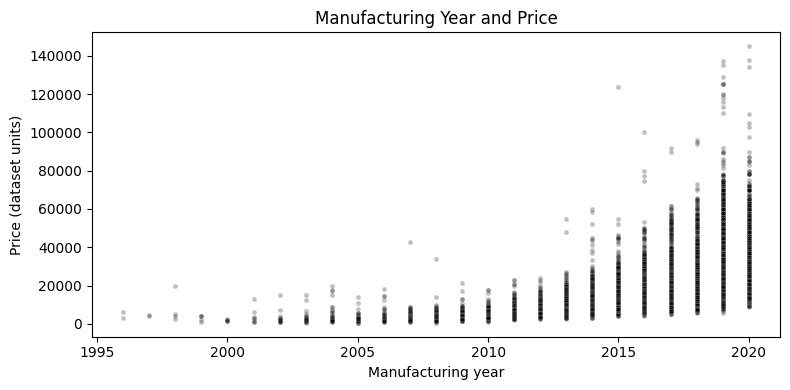

In [21]:
plt.figure(figsize=(8, 4))
sns.scatterplot(x="year", y="price", data=df, color="black", alpha=0.25, s=12)
plt.title("Manufacturing Year and Price")
plt.xlabel("Manufacturing year")
plt.ylabel("Price (dataset units)")
plt.tight_layout()
plt.show()

**Observation:** Newer cars generally tend to have higher prices in this dataset, though cars of the same year can still have very different prices.

## 13. Chart 6 - Mileage and price

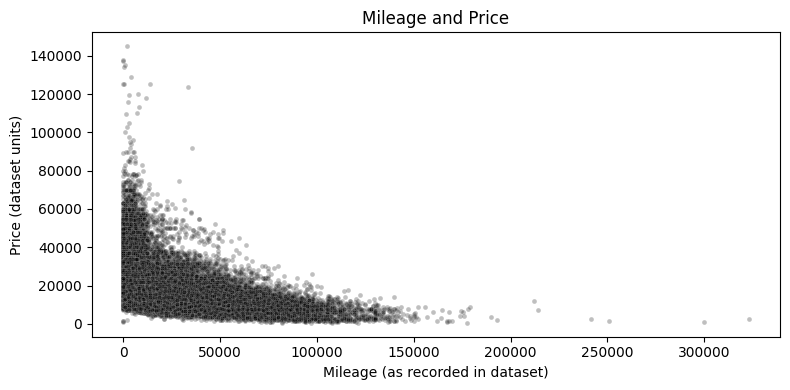

In [22]:
plt.figure(figsize=(8, 4))
sns.scatterplot(x="mileage", y="price", data=df, color="black", alpha=0.25, s=12)
plt.title("Mileage and Price")
plt.xlabel("Mileage (as recorded in dataset)")
plt.ylabel("Price (dataset units)")
plt.tight_layout()
plt.show()

**Observation:** Cars with higher mileage often have lower prices, but mileage does not explain every price difference.

## 14. Simple relationship check

In [23]:
print(df[["price", "year", "mileage", "engineSize"]].corr().round(2))

            price  year  mileage  engineSize
price        1.00  0.52    -0.43        0.63
year         0.52  1.00    -0.75       -0.03
mileage     -0.43 -0.75     1.00        0.12
engineSize   0.63 -0.03     0.12        1.00


**How to read this table:** Values near +1 show a positive relationship, values near -1 show a negative relationship, and values near 0 show a weak linear relationship. Correlation does not prove cause and effect.

## 15. Findings and limitations
1. Petrol is the most common fuel type in this dataset.
2. The median price is higher for hybrid cars than petrol cars, but this comparison does not explain why.
3. Newer manufacturing year has a positive relationship with price.
4. Mileage has a negative relationship with price.
5. Engine size also has a positive relationship with price in the numerical correlation table.

The dataset contains only five electric cars, so electric-car comparisons are uncertain. Brand, model, year, mileage and engine size can all differ between fuel groups. The file does not include repair history or maintenance records, so it cannot measure reliability. The currency and original public source URL were not included with the supplied CSV. This analysis describes relationships and does not prove causes.

## Conclusion
This analysis used basic Python tools to inspect and clean the cars dataset, summarize its columns and compare prices with fuel type, manufacturing year and mileage. The main lesson is that fuel type is associated with different observed price distributions, but other car features may also help explain the differences.